In [1]:
import pandas as pd
import numpy as np
import re

import scipy.stats as ss
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import multinomial
from ssrm_test import ssrm_test
np.random.seed(1)

import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(r'E:\Projects\portfolio\ab_srm_validator\materials\exp1.csv')
df.head()

,user_id,date,url
0,d48e135cA,2017-11-01 00:00:00,/dummy.txt?action=viewbull_open_photo_fotorama
1,7885b94eB,2017-11-01 00:00:00,/city/directory/57689556.html
2,9382d05eB,2017-11-01 00:00:01,/directory/?_lightweight=1&_origuterm=abond-fr...
3,feaaa515A,2017-11-01 00:00:01,/dummy.txt?action=mobileapp_native_banner_show
4,feaaa515A,2017-11-01 00:00:01,/dummy.txt?action=mobileVersion


In [4]:
df.shape

(4161573, 3)

In [5]:
# Проверка пропущенных значений
df.isna().sum()

user_id    0
date       0
url        0
dtype: int64

In [6]:
df.dtypes

user_id    object
date       object
url        object
dtype: object

## <font color="orange">Подготовка набора данных</font>

In [7]:
df['date'] = pd.to_datetime(df.date)
df['user_id_clean'] = df['user_id'].str[:-1]
df['group'] = df['user_id'].astype(str).str[-1]
# Столбец с отметкой целевого события 
pattern = r'/(city/directory/[^/]+\.html|good/[^/]+/(owner_info|ajax_contact)|bulletin/[^/]+/(owner_info|ajax_contact))'
# Создаём новую колонку с 1, если событие соответствует шаблону, иначе — 0
df['event_flag'] = df['url'].apply(lambda x: 1 if re.search(pattern, x) else 0)
df = df.sort_values('date')

df.head()

,user_id,date,url,user_id_clean,group,event_flag
0,d48e135cA,2017-11-01 00:00:00,/dummy.txt?action=viewbull_open_photo_fotorama,d48e135c,A,0
1,7885b94eB,2017-11-01 00:00:00,/city/directory/57689556.html,7885b94e,B,1
2,9382d05eB,2017-11-01 00:00:01,/directory/?_lightweight=1&_origuterm=abond-fr...,9382d05e,B,0
3,feaaa515A,2017-11-01 00:00:01,/dummy.txt?action=mobileapp_native_banner_show,feaaa515,A,0
4,feaaa515A,2017-11-01 00:00:01,/dummy.txt?action=mobileVersion,feaaa515,A,0


## <font color="orange">Провкерка на ошибку несоответсвия выборки (SRM)</font>  

Несоответствие отношения выборки или SRM (sample ratio mismatch):  
эксперимент может давать смещенные результаты, так как соотношение выборок в ходе процесса сплитования искажается.

In [8]:
df.user_id.value_counts()

user_id
e29599eaB    999
3749be8dB    998
4e41ca1eA    998
14d1ad22A    997
48aca6c2A    996
            ... 
93428351A      5
96714e56A      5
4e2e930aB      5
b355e848A      5
9da81587B      5
Name: count, Length: 71005, dtype: int64

In [9]:
total_us = df.user_id.unique()
a_us = df['user_id_clean'][df.group == 'A'].unique()
b_us = df['user_id_clean'][df.group == 'B'].unique()
common = set(a_us) & set(b_us)
a_num_observations = df['user_id_clean'][df.group == 'A']
b_num_observations = df['user_id_clean'][df.group == 'B']

print(f'Общее кол-во уникальных пользователей: {len(total_us)}')
print(f'Кол-во уникальных пользователей группы A: {len(a_us)}')
print(f'Кол-во уникальных пользователей группы B: {len(b_us)}')
print(f'Кол-во пользователей входящих во все группв: {len(common)}')
print(f'Кол-во наблюдений группы A: {len(a_num_observations)}')
print(f'Кол-во наблюдений группы B: {len(b_num_observations)}')

Общее кол-во уникальных пользователей: 71005
Кол-во уникальных пользователей группы A: 38341
Кол-во уникальных пользователей группы B: 32664
Кол-во пользователей входящих во все группв: 0
Кол-во наблюдений группы A: 2237244
Кол-во наблюдений группы B: 1924329


## Проверка SRM с помощью статистических тестов Chi-квадрат и Z-тест
### Обоснование выбора тестов

> **Единица анализа** — уникальный пользователь в одной из двух категорий (A/B), наблюдения независимы (пересечений между группами нет). Это категориальные данные с фиксированным плановым соотношением 50/50 — под такую постановку подходят именно тесты на доли.

1. **Хи-квадрат (Пирсона):** Отраслевой стандарт проверки SRM (используется *Optimizely*, *GrowthBook* и др.). Обобщается на мультивариантные тесты (A/B/C/D) и произвольные плановые доли. Не требует нормальности выборки.
2. **Z-тест на одну пропорцию:** Проверяет ту же гипотезу \(H_0: p_A = 0.5\), но даёт направление перекоса (знак \(Z\) указывает, какая группа недобрала) и интуитивно интерпретируемую величину отклонения в стандартных ошибках.

---

### Почему оба теста?

Математически для двух групп \($Z^2 = \chi^2$\) (в текущем исследовании \($21.37^2 \approx 456.8 \approx 453.89$\) — расхождение всего \($\approx 0.6\%$\) из-за разных формул дисперсии). 

Запускаются оба метода как **взаимная проверкуа реализации**: согласие двух независимых библиотек (`scipy` и `statsmodels`) полностью исключает баг в коде. При этом:
*   **Хи-квадрат** идёт в отчёт как «стандартный SRM-тест»;
*   **Z-тест** используется для диагностики направления перекоса.

---

### SSRM (Optimizely)

Метод из другого семейства — последовательный, он следит за \(p\)-value по мере накопления трафика. Отвечает не просто на вопрос *«есть ли SRM»*, а *«когда он стал виден»*. 

> Независимость метода + полное согласие с двумя классическими критериями = вывод устойчив к выбору инструмента.

### 1. Проверка с помощью критерия chi-квадрат  
работает с оценкой долей и частот появления значений в данных

**Расчеты на основе уникальных пользователей.**  
Почему? Один пользователь может генерировать до 999 событий,  
скармливая тестам 4.16 млн строк, искусственно завышается размер выборки (в даном случае ~58 раз).  
Тесты думают, что в наборе данных 4 миллиона независимых пользователей, из-за чего p-value падает до 0, а Z-статистика раздувается до невероятных размеров.

In [10]:
# Текущее число пользователей в тестовой и контрольной группах
observed = [len(a_us), len(b_us)]
# Ожидаемое соотношение между двумя группами (в процентах)
ratio = 50
# С каким уровнем значимости готовы проверять гипотезу о том, что есть SRM
alpha = 0.05

total_traffic = sum(observed)

expected = [ (total_traffic * ratio)/100, (total_traffic * (100 - ratio)/100) ] # ожидаемые размеры групп если бы ratio выполнялось полностью
print('Фактические размеры выборок:', observed)
print('Ожидаемые объем выборки:', expected)

chi = ss.chisquare(observed, f_exp = expected) # расчет результата точечной оценки доли через хи-квадрат критерий

if chi[1] < alpha:
    print('SRM, присутствует!!!')
else:
    print('SRM отсутствует')
print(chi)

Фактические размеры выборок: [38341, 32664]
Ожидаемые объем выборки: [35502.5, 35502.5]
SRM, присутствует!!!
Power_divergenceResult(statistic=453.88816280543625, pvalue=1.0279021197235558e-100)


### Пояснение результата
**p-value** — вероятность получить такое (или ещё большее) расхождение случайно, если на самом деле сплит честный (50/50).  
**statistic** — число, показывающее, насколько сильно фактические частоты отличаются от ожидаемых.

В случае проведенного теста:

statistic ≈ 453.89. Интерпретация: чем больше статистика, тем сильнее расхождение. Здесь расхождение очень серьёзное, отклонение составляет ≈ 2 838 уникальных пользователей в каждой группе (38 341 факт против 35 502.5 ожидания).  
pvalue ≈ 1.03e-100 означает вероятность получить такое распределение случайно равна 1 * 10 в минус 100 степени. Это исчезающе малая величина (p-value ≪ 0.001).

**Практический вывод:** отклоняем гипотезу о равномерном сплите. Разница статистически значима и не случайна.  
**SRM присутствует.** Соотношение уникальных пользователей не 50/50, а примерно 54.0% / 46.0%:  
*38341 / (38341 + 32664) ≈ 0.540 (Группа A)*  
*32664 / (38341 + 32664) ≈ 0.460 (Группа B)*  

На выборке в 71 тыс. уникальных пользователей отклонение в 8 п.п. — это очень серьёзный перекос, указывающий на системную ошибку в механизме сплитования.

| Поле | Значение | Смысл |
| :--- | :--- | :--- |
| statistic | 453.89 | Насколько факт отличается от ожидания (больше = хуже) |
| pvalue | 1.03e-100  | Вероятность такого расхождения случайно **$\approx 1 \times 10^{-100}$**|
| Вывод | SRM есть | Сплит нарушен, тесту доверять нельзя |

### 2. Проверка с использованием z-теста с одной пропорцией

In [11]:
# z-тест на одну пропорцию
stat, pval = proportions_ztest(count=observed[0], nobs=sum(observed), value=0.5) # считаем точечную оценку доли для z-теста
print('Z-статистика: ', stat, '\np-value: ', pval)

if pval < alpha:
    print('SRM при выбранном alpha присутствует')
else:
    print('SRM отсутствует')

Z-статистика:  21.373072702883483 
p-value:  2.3794647423416367e-101
SRM при выбранном alpha присутствует


#### Пояснение результата  

**Z-статистика** показывает, на сколько стандартных ошибок ($SE$) наблюдаемая доля группы отклоняется от ожидаемой ($P_0 = 0.5$).

*   **Масштаб отклонения** составляет **21.37 $SE$**. Это катастрофически далеко за пределами нормы. Обычно критическим порогом считается $|Z| > 2…3$, здесь же аномалия видна невооруженным глазом.
*   **Причина такого Z-значения:** На выборке в **71 005** уникальных пользователей стандартная ошибка ($SE$) становится очень маленькой ($\approx 0.0018$). Из-за этого отклонение в 8 п.п. раздувает Z-критерий до огромных масштабов.

#### Дисбаланс трафика в цифрах (по уникальным пользователям):

*   **Группа A:** $38\,341 / 71\,005 \approx 0.540$ — перебор около 4 п.п. относительно нормы.
*   **Группа B:** $32\,664 / 71\,005 \approx 0.460$ — недобор около 4 п.п. относительно нормы.

> **Вывод:** Распределение трафика критически нарушено. Группа A получила избыточный объем пользователей, а группа B недополучила их.

**$p$-value $\approx 2.38 \times 10^{-101}$** — полностью подтверждает результаты теста хи-квадрат. Вероятность получить такое распределение случайно равна исчезающе малому числу (фактически нулю). Сплит-система сломана, результатам эксперимента доверять нельзя.


### Проверка с использованием SSRM (Optimizely). Последовательное наблюдение за SRM  
SSRM, это попытка следить за SRM последовательно, делая это через определенное количество пользователей и давать ответ, что SRM присутствует.

(71005, 2)


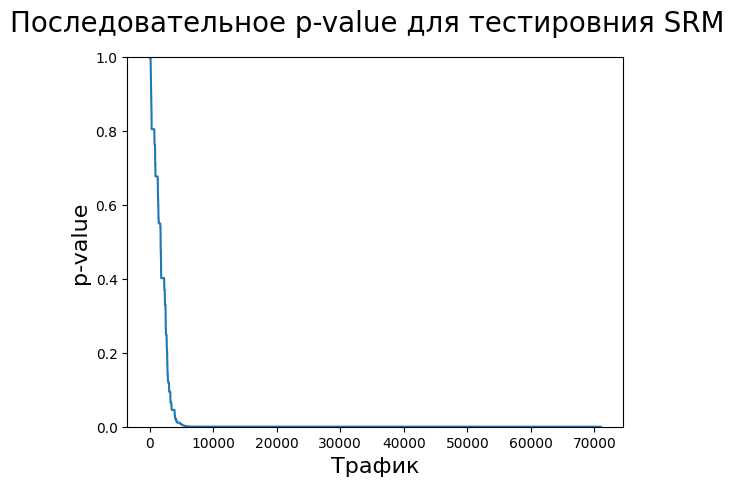

In [12]:
# ПОДГОТОВКА ДАННЫХ
# Читаем данные и оставляем уникальных пользователей

users = df.drop_duplicates('user_id_clean')[['user_id_clean', 'group']].copy()

# Кодируем group в one-hot: [1, 0] для A, [0, 1] для B
users['is_A'] = (users['group'] == 'A').astype(int)
users['is_B'] = (users['group'] == 'B').astype(int)

# Формируем матрицу (порядок столбцов = порядок в p_0)
data = users[['is_A', 'is_B']].values
print(data.shape)  # (число уникальных пользователей, 2)

# Задаём ожидаемое распределение
p_0 = [0.5, 0.5]

# Запускаем последовательный тест
pvals = ssrm_test.sequential_p_values(data, p_0)
fig = plt.figure()
plt.plot(pvals)
fig.suptitle("Последовательное p-value для тестировния SRM", fontsize=20)
plt.xlabel("Трафик", fontsize=16)
plt.ylabel("p-value", fontsize=16)
plt.ylim(0, 1)
plt.show()

По оси `y` расположены значения `p-value` в каждом из проверяемых тестов.  
По оси `x` трафик, на котором производится проверка гипотезы о том, есть **SRM** или его нет. 

In [13]:
n = len(total_us)
below_alpha = np.array(pvals) < 0.05
if below_alpha.any():
    sig_reached = np.argmax(below_alpha)
    print(f"SSRM отклонило нулевую гипотезу... после {sig_reached} пользователей")
    print(f"Это {round(100 * sig_reached / n, 3)}% от общего числа пользователей для этого эксперимента")
else:
    print("SSRM не обнаружило SRM. Сплит ровный.")

SSRM отклонило нулевую гипотезу... после 3430 пользователей
Это 4.831% от общего числа пользователей для этого эксперимента


## <font color="orange">Итоговые выводы и рекомендации</font>

По результатам проверки данных эксперимента обнаружено **критическое несоответствие соотношения выборок** (Sample Ratio Mismatch, SRM).

### Что было обнаружено

*   **Ожидаемое соотношение групп:** 50% / 50%.
*   **Фактическое соотношение:** 54.0% (Группа A) / 46.0% (Группа B).

Все три метода проверки (Хи-квадрат, Z-тест и последовательный тест SSRM) единогласно подтвердили, что этот перекос не является случайностью. Полученные $p$-value экстремально малы (порядка $10^{-100}$), что на много порядков ниже любого стандартного уровня значимости (например, $\alpha = 0.05$ или даже $\alpha = 0.001$).  
Перекос стал статистически заметным уже на **4.8%** трафика.


---

### Почему это важно?

При наличии SRM **нельзя доверять результатам эксперимента**. Если есть разница в конверсии (`event_flag`) между группами, то не возможно понять, это эффект от новой фичи или просто следствие того, что в группу `A` попали более активные пользователи (или их просто больше). 

> **Риск:** Любые решения на основе этих данных могут привести к финансовым потерям и неверным продуктовым выводам.

---

### Рекомендация

1.  **Не принимать продуктовые решения** на основе этого теста. Анализ целевой метрики (`event_flag`) не имеет смысла до устранения проблемы.
2.  **Провести технический аудит метода сплитования** (Randomization/Allocation System):
    *   **Проверить алгоритм хеширования** и распределения пользователей по бакетам (возможно, хеш-функция дает перекос).
    *   **Проверить логирование:** не теряются ли логи пользователей группы `B` (ошибки логирования, падения клиента).
    *   **Проверить фильтрацию данных на этапе ETL** (например, если есть фильтр *«отсеять пользователей с < 5 событиями»*, не отсекает ли он группу `B` чаще, чем группу `A`).
3.  **Перезапустить эксперимент** после исправления бага.
4.  *(Опционально)* Если лог назначения групп (кто в какой группе изначально) сохранен отдельно, можно запросить его, чтобы понять, где именно произошла утечка, на этапе сплитования или на этапе записи событий.

---

### Что было сделано?

Была проведена **трехуровневую проверка**:
*   Базовые тесты Хи-квадрат и Z-тест на уникальных пользователях;
*   Последовательный тест SSRM от *Optimizely*.

Ошибка поймана на ранней стадии.